In [1]:
# Imports
import os
import sys
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report, f1_score
from sklearn.utils.class_weight import compute_class_weight

from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# ✅ FIX Kaggle: Forza flush output per vedere i log in tempo reale
import functools
print = functools.partial(print, flush=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("✅ Imports completati")

✅ Imports completati


In [2]:
!pip install timm ranger21 -q
import timm
from ranger21 import Ranger21

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [3]:
# Configuration
class Config:
    # Training
    NUM_EPOCHS = 50
    BATCH_SIZE = 16
    LEARNING_RATE = 3e-4
    WEIGHT_DECAY = 1e-3
    
    # Image
    TARGET_SIZE = 224
    GRAY_BACKGROUND = 0
    
    # Maschera
    MASK_DILATION_PX = 5
    
    # Model
    MODEL_NAME = 'efficientnet_b3'
    NUM_CLASSES = 2
    DROPOUT = 0.6
    USE_CBAM = True
    
    # Loss
    FOCAL_ALPHA = 0.6
    FOCAL_GAMMA = 3.0
    LABEL_SMOOTHING = 0.15
    
    # Mixup Augmentation
    MIXUP_ENABLED = True
    MIXUP_ALPHA = 0.2
    
    # Early stopping
    PATIENCE = 10
    
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Device: {Config.DEVICE}")
print(f"Model: {Config.MODEL_NAME} + CBAM")
print(f"Mask dilation: {Config.MASK_DILATION_PX}px")
print(f"Target: Balanced Accuracy > 75%")

Device: cuda
Model: efficientnet_b3 + CBAM
Mask dilation: 5px
Target: Balanced Accuracy > 75%


## Data Loading

In [ ]:
def load_patient_data(csv_path, images_dir):
    df = pd.read_excel(csv_path)
    patients_dict = defaultdict(list)
    
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading data"):
        img_name = row['US']
        mask_name = row['MASK']
        label = row['LABEL']
        
        if label == 2:
            continue
        
        patient_id = Path(img_name).stem.split('_')[0]
        
        patients_dict[patient_id].append({
            'img_path': str(Path(images_dir) / img_name),
            'mask_path': str(Path(images_dir) / mask_name),
            'img_name': img_name,
            'label': label
        })
    
    patients = []
    for pid, samples in sorted(patients_dict.items(), key=lambda x: int(x[0])):
        if len(samples) == 0:
            continue
        labels = [s['label'] for s in samples]
        major_label = int(np.argmax(np.bincount(labels)))
        patients.append({
            'patient_id': pid,
            'samples': samples,
            'major_label': major_label
        })
    
    return patients

INPUT_DIRECTORY = '/kaggle/input/breast-lesions/'
IMG_DIRECTORY = INPUT_DIRECTORY + 'train/images'
LABELS_PATH = INPUT_DIRECTORY + 'train/train_metadata.xlsx'

train_data = load_patient_data(LABELS_PATH, IMG_DIRECTORY)
print(f"\n✅ Loaded {len(train_data)} patients (excluding normal)")

n_benign = sum(len([s for s in p['samples'] if s['label'] == 0]) for p in train_data)
n_malignant = sum(len([s for s in p['samples'] if s['label'] == 1]) for p in train_data)
print(f"   Benign samples: {n_benign}")
print(f"   Malignant samples: {n_malignant}")
print(f"   Ratio: {n_malignant / n_benign:.2f}")

## Pre-processing Functions

In [5]:
def has_colors(img, sat_thresh=40, delta_thresh=20, white_brightness_thresh=200, 
               white_sat_thresh=30, red_sat_thresh=50, blue_sat_thresh=50):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    b, g, r = cv2.split(img)
    r, g, b = r.astype(np.int16), g.astype(np.int16), b.astype(np.int16)
    
    delta = np.maximum.reduce([np.abs(r - g), np.abs(r - b), np.abs(g - b)])
    mask = np.logical_or.reduce([
        np.logical_and(delta > delta_thresh, s > sat_thresh),
        (s < white_sat_thresh) & (v > white_brightness_thresh),
        ((h < 15) | (h > 165)) & (s > red_sat_thresh),
        ((h >= 100) & (h <= 130)) & (s > blue_sat_thresh)
    ]).astype(np.uint8) * 255
    
    return np.sum(mask) > 0, mask

def inpaint(img):
    detected, mask = has_colors(img)
    if detected:
        return cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA)
    return img

def apply_median_filter(image, kernel_size=5):
    return cv2.medianBlur(image.astype(np.uint8), kernel_size)

def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)

def apply_zscore_normalization(image):
    image = image.astype(np.float32)
    mean, std = np.mean(image), np.std(image)
    return (image - mean) / std if std > 0 else image - mean

In [6]:
def create_masked_image(image, mask, dilation_px=5, gray_value=128):
    if dilation_px > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilation_px*2+1, dilation_px*2+1))
        mask_dilated = cv2.dilate(mask, kernel, iterations=1)
    else:
        mask_dilated = mask.copy()
    
    masked_image = np.full_like(image, gray_value, dtype=np.uint8)
    
    mask_bool = mask_dilated > 127
    masked_image[mask_bool] = image[mask_bool]
    
    return masked_image, mask_dilated


def crop_to_lesion(image, mask, target_size=224, gray_value=128):
    coords = np.where(mask > 0)
    if len(coords[0]) == 0:
        return np.full((target_size, target_size), gray_value, dtype=np.float32)
    
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()
    
    cropped = image[y_min:y_max+1, x_min:x_max+1].copy()
    
    h, w = cropped.shape
    if h == 0 or w == 0:
        return np.full((target_size, target_size), gray_value, dtype=np.float32)
    
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    new_h, new_w = max(1, new_h), max(1, new_w)
    
    cropped_resized = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    
    output = np.full((target_size, target_size), gray_value, dtype=np.float32)
    pad_h = (target_size - new_h) // 2
    pad_w = (target_size - new_w) // 2
    output[pad_h:pad_h+new_h, pad_w:pad_w+new_w] = cropped_resized
    
    return output

## Edge Regularity (Auxiliary Loss Support)

In [7]:
def compute_edge_regularity(masked_image_uint8):
    sobelx = cv2.Sobel(masked_image_uint8, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(masked_image_uint8, cv2.CV_64F, 0, 1, ksize=3)
    edges = np.sqrt(sobelx**2 + sobely**2)
    
    edges = (edges / (edges.max() + 1e-8) * 255).astype(np.uint8)
    
    _, edge_mask = cv2.threshold(edges, 50, 255, cv2.THRESH_BINARY)
    
    contours, _ = cv2.findContours(edge_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if len(contours) == 0:
        return 0.5
    
    largest_contour = max(contours, key=cv2.contourArea)
    
    perimeter = cv2.arcLength(largest_contour, True)
    area = cv2.contourArea(largest_contour)
    
    if area < 10:
        return 0.5
    
    circularity = 4 * np.pi * area / (perimeter ** 2 + 1e-8)
    
    regularity = np.clip(circularity, 0, 1)
    
    return regularity


class AdvancedImageAugmentation:

    def __init__(self, p_flip=0.5, p_rotate=0.4, p_elastic=0.3, p_grid=0.2, 
                 p_bright=0.5, p_contrast=0.5, p_noise=0.2, p_blur=0.2):
        self.p_flip = p_flip
        self.p_rotate = p_rotate
        self.p_elastic = p_elastic
        self.p_grid = p_grid
        self.p_bright = p_bright
        self.p_contrast = p_contrast
        self.p_noise = p_noise
        self.p_blur = p_blur
    
    def elastic_transform(self, image, alpha=30, sigma=4):
        random_state = np.random.RandomState(None)
        shape = image.shape
        
        dx = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32), (0, 0), sigma) * alpha
        dy = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32), (0, 0), sigma) * alpha
        
        x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
        map_x = (x + dx).astype(np.float32)
        map_y = (y + dy).astype(np.float32)
        
        img_out = cv2.remap(image.astype(np.float32), map_x, map_y, cv2.INTER_LINEAR, borderValue=128)
        return img_out.astype(np.uint8)
    
    def grid_distortion(self, image, num_steps=5, distort_limit=0.15):
        h, w = image.shape
        
        x_steps = np.linspace(0, w, num_steps)
        y_steps = np.linspace(0, h, num_steps)
        
        x_offsets = np.zeros(num_steps)
        y_offsets = np.zeros(num_steps)
        x_offsets[1:-1] = np.random.uniform(-distort_limit * w / num_steps, 
                                              distort_limit * w / num_steps, num_steps - 2)
        y_offsets[1:-1] = np.random.uniform(-distort_limit * h / num_steps, 
                                              distort_limit * h / num_steps, num_steps - 2)
        
        map_x = np.zeros((h, w), dtype=np.float32)
        map_y = np.zeros((h, w), dtype=np.float32)
        
        for i in range(h):
            for j in range(w):
                map_x[i, j] = j + np.interp(j, x_steps, x_offsets)
                map_y[i, j] = i + np.interp(i, y_steps, y_offsets)
        
        map_x = np.clip(map_x, 0, w - 1)
        map_y = np.clip(map_y, 0, h - 1)
        
        img_out = cv2.remap(image.astype(np.float32), map_x, map_y, cv2.INTER_LINEAR, borderValue=128)
        return img_out.astype(np.uint8)
    
    def __call__(self, image):
        img = image.copy().astype(np.float32)
        
        # Flip orizzontale
        if np.random.rand() < self.p_flip:
            img = cv2.flip(img, 1)
        
        # Flip verticale
        if np.random.rand() < self.p_flip:
            img = cv2.flip(img, 0)
        
        # Rotazione
        if np.random.rand() < self.p_rotate:
            angle = np.random.uniform(-20, 20)
            h, w = img.shape
            M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
            img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=128)
        
        # Elastic Deformation
        if np.random.rand() < self.p_elastic:
            img = self.elastic_transform(img, alpha=25, sigma=4)
        
        # Grid Distortion
        if np.random.rand() < self.p_grid:
            img = self.grid_distortion(img, num_steps=4, distort_limit=0.15)
        
        # Brightness
        if np.random.rand() < self.p_bright:
            brightness_delta = np.random.uniform(0.75, 1.25)
            img = np.clip(img * brightness_delta, 0, 255)
        
        # Contrast
        if np.random.rand() < self.p_contrast:
            contrast_delta = np.random.uniform(0.75, 1.25)
            mean_val = np.mean(img)
            img = np.clip(mean_val + contrast_delta * (img - mean_val), 0, 255)
        
        # Gaussian Noise
        if np.random.rand() < self.p_noise:
            noise = np.random.normal(0, np.random.uniform(5, 15), img.shape)
            img = np.clip(img + noise, 0, 255)
        
        # Gaussian Blur
        if np.random.rand() < self.p_blur:
            kernel_size = np.random.choice([3, 5])
            img = cv2.GaussianBlur(img, (kernel_size, kernel_size), 0)
        
        return np.clip(img, 0, 255).astype(np.uint8)


## Dataset

In [8]:
class LesionClassificationDataset(Dataset):

    def __init__(self, patients, augment=False, config=Config):
        self.samples = []
        for patient in patients:
            self.samples.extend(patient['samples'])
        
        self.augment = augment
        self.config = config
        self.img_aug = AdvancedImageAugmentation() if augment else None
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        # 1. Load image and mask
        img_bgr = cv2.imread(sample['img_path'])
        mask_bgr = cv2.imread(sample['mask_path'])
        mask_gray = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2GRAY)
        mask_binary = (mask_gray > 127).astype(np.uint8) * 255
        
        # 2. Inpainting
        img_inpainted = inpaint(img_bgr)
        
        # 3. Convert to grayscale
        img_gray = cv2.cvtColor(img_inpainted, cv2.COLOR_BGR2GRAY)
        
        # 4. Median filter
        img_denoised = apply_median_filter(img_gray)
        
        # 5. CLAHE
        img_clahe = apply_clahe(img_denoised)
        
        # 6. Crea masked image (con dilatazione 5px)
        masked_img, mask_dilated = create_masked_image(
            img_clahe, mask_binary,
            dilation_px=self.config.MASK_DILATION_PX,
            gray_value=self.config.GRAY_BACKGROUND
        )
        
        # 7. Crop al bounding box della lesione
        img_cropped = crop_to_lesion(
            masked_img, mask_dilated,
            target_size=self.config.TARGET_SIZE,
            gray_value=self.config.GRAY_BACKGROUND
        )
        
        # 8. Image augmentation (training only)
        if self.augment and self.img_aug is not None:
            img_cropped = self.img_aug(img_cropped)
        
        # 9. Normalizza (0-1) e converti in tensor 3-channel
        img_normalized = img_cropped.astype(np.float32) / 255.0
        img_normalized = np.ascontiguousarray(img_normalized)
        img_tensor = torch.from_numpy(img_normalized).float()
        img_tensor = img_tensor.unsqueeze(0).repeat(3, 1, 1)  # 1 -> 3 channels
        
        # Label
        label = sample['label']  # 0=benign, 1=malignant
        
        edge_regularity = compute_edge_regularity(img_cropped.astype(np.uint8))
        
        edge_label = 1 if edge_regularity > 0.5 else 0
        
        return {
            'image': img_tensor,
            'label': torch.tensor(label, dtype=torch.long),
            'edge_label': torch.tensor(edge_label, dtype=torch.long),
            'edge_regularity': torch.tensor(edge_regularity, dtype=torch.float32)
        }

## Model

In [9]:
class MultiHeadSpatialAttention(nn.Module):
    def __init__(self, in_channels, num_heads=3):
        super().__init__()
        self.num_heads = num_heads
        kernel_sizes = [3, 5, 7]
        self.attentions = nn.ModuleList([
            nn.Conv2d(2, 1, ks, padding=ks//2, bias=False) for ks in kernel_sizes
        ])
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        combined = torch.cat([avg_out, max_out], dim=1)
        
        att_maps = []
        for att_layer in self.attentions:
            att = self.sigmoid(att_layer(combined))
            att_maps.append(att)
        
        final_att = torch.mean(torch.stack(att_maps), dim=0)
        return x * final_att


class EdgeAwareModule(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        self.register_buffer('sobel_x', torch.tensor([
            [-1., 0., 1.],
            [-2., 0., 2.],
            [-1., 0., 1.]
        ]).unsqueeze(0).unsqueeze(0))
        
        self.register_buffer('sobel_y', torch.tensor([
            [-1., -2., -1.],
            [0., 0., 0.],
            [1., 2., 1.]
        ]).unsqueeze(0).unsqueeze(0))
        
        self.edge_processor = nn.Sequential(
            nn.Conv2d(2, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )
    
    def forward(self, x):
        if x.shape[1] == 3:
            x_gray = x.mean(dim=1, keepdim=True)
        else:
            x_gray = x
        
        edges_x = F.conv2d(x_gray, self.sobel_x, padding=1)
        edges_y = F.conv2d(x_gray, self.sobel_y, padding=1)
        edges = torch.cat([edges_x, edges_y], dim=1)
        
        edge_features = self.edge_processor(edges)
        return edge_features.flatten(1)


class ROIFocusedAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.channel_att = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels//16, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels//16, in_channels, 1),
            nn.Sigmoid()
        )
        self.multi_head_spatial = MultiHeadSpatialAttention(in_channels, num_heads=3)
    
    def forward(self, x):
        ca = self.channel_att(x)
        x = x * ca
        x = self.multi_head_spatial(x)
        return x


class EfficientNetWithROIAwareCBAM(nn.Module):
    def __init__(self, num_classes=2, dropout=0.4, pretrained=True):
        super().__init__()
        
        self.backbone = timm.create_model(
            'efficientnet_b3',
            pretrained=pretrained,
            num_classes=0,
            global_pool=''
        )
        
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            features = self.backbone(dummy)
            features_dim = features.shape[1]
            print(f"   Backbone output: {features.shape}")
        
        self.roi_attention = ROIFocusedAttention(features_dim)
        
        self.edge_module = EdgeAwareModule(in_channels=3)
        edge_feature_dim = 64
        
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        
        fusion_dim = features_dim + edge_feature_dim
        self.fusion_layer = nn.Sequential(
            nn.Linear(fusion_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout)
        )
        
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
        
        self.aux_classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )
        

    def forward(self, x, return_aux=False):
        spatial_features = self.backbone(x)  # (B, C, H, W)
        spatial_features = self.roi_attention(spatial_features)  # (B, C, H, W) con ROI attention
        
        spatial_pooled = self.global_pool(spatial_features)  # (B, C, 1, 1)
        spatial_pooled = spatial_pooled.flatten(1)  # (B, C)
        
        edge_features = self.edge_module(x)  # (B, edge_feature_dim)
        
        fused = torch.cat([spatial_pooled, edge_features], dim=1)  # (B, C + edge_dim)
        fused = self.fusion_layer(fused)  # (B, 512)
        
        main_logits = self.classifier(fused)
        
        if return_aux:
            aux_logits = self.aux_classifier(fused)
            return main_logits, aux_logits
        
        return main_logits

## Loss Function

In [10]:
class WeightedFocalLoss(nn.Module):
    def __init__(self, class_weights=None, gamma=2.5, label_smoothing=0.15):
        super().__init__()
        self.class_weights = class_weights
        self.gamma = gamma
        self.label_smoothing = label_smoothing
    
    def forward(self, logits, targets):
        batch_size = logits.shape[0]
        
        if self.label_smoothing > 0:
            n_classes = logits.shape[1]
            soft_targets = torch.ones_like(logits) * self.label_smoothing / (n_classes - 1)
            soft_targets.scatter_(1, targets.unsqueeze(1), 1 - self.label_smoothing)
            log_probs = F.log_softmax(logits, dim=1)
            ce_loss = -(soft_targets * log_probs).sum(dim=1)
        else:
            ce_loss = F.cross_entropy(logits, targets, reduction='none')
        
        probs = F.softmax(logits, dim=1)
        p_t = probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        focal_weight = (1 - p_t) ** self.gamma
        
        if self.class_weights is not None:
            class_weight_t = self.class_weights[targets]
        else:
            class_weight_t = torch.ones(batch_size, device=logits.device)
        
        weighted_focal_loss = focal_weight * class_weight_t * ce_loss
        return weighted_focal_loss.mean()


class CombinedLossV2(nn.Module):
    def __init__(self, class_weights=None, alpha=0.85, gamma=2.5, label_smoothing=0.15):
        super().__init__()
        self.alpha = alpha
        self.weighted_focal = WeightedFocalLoss(
            class_weights=class_weights, 
            gamma=gamma, 
            label_smoothing=label_smoothing
        )
        self.edge_loss = nn.CrossEntropyLoss(label_smoothing=0.05)
    
    def forward(self, main_logits, main_targets, aux_logits, aux_targets):
        main_loss = self.weighted_focal(main_logits, main_targets)
        
        aux_loss = self.edge_loss(aux_logits, aux_targets)
        
        total_loss = self.alpha * main_loss + (1 - self.alpha) * aux_loss
        
        return total_loss, main_loss.item(), aux_loss.item()




## Training Functions

In [11]:
def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    
    return mixed_x, y_a, y_b, lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    loss_a = criterion.weighted_focal(pred, y_a)
    loss_b = criterion.weighted_focal(pred, y_b)
    return lam * loss_a + (1 - lam) * loss_b


In [12]:
def train_one_epoch(model, dataloader, optimizer, criterion, device, scheduler=None, use_mixup=True, mixup_alpha=0.2):
    model.train()
    total_loss = 0
    main_loss_sum = 0
    aux_loss_sum = 0
    all_preds = []
    all_labels = []
    
    pbar = tqdm(dataloader, desc="Train", leave=False)
    for batch in pbar:
        images = batch['image'].to(device)
        labels = batch['label'].to(device)
        edge_labels = batch['edge_label'].to(device)
        
        optimizer.zero_grad()
        
        if use_mixup and np.random.rand() < 0.5:
            images, labels_a, labels_b, lam = mixup_data(images, labels, alpha=mixup_alpha)
            
            main_logits, aux_logits = model(images, return_aux=True)
            
            main_loss = mixup_criterion(criterion, main_logits, labels_a, labels_b, lam)
            
            aux_loss = criterion.edge_loss(aux_logits, edge_labels)
            
            loss = criterion.alpha * main_loss + (1 - criterion.alpha) * aux_loss
            main_loss_val = main_loss.item()
            aux_loss_val = aux_loss.item()
        else:
            main_logits, aux_logits = model(images, return_aux=True)
            
            loss, main_loss_val, aux_loss_val = criterion(main_logits, labels, aux_logits, edge_labels)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        if scheduler is not None:
            scheduler.step()
        
        total_loss += loss.item()
        main_loss_sum += main_loss_val
        aux_loss_sum += aux_loss_val
        
        if not (use_mixup and np.random.rand() < 0.5):
            preds = torch.argmax(main_logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
        
        pbar.set_postfix({
            'loss': f"{loss.item():.4f}",
            'main': f"{main_loss_val:.4f}",
            'aux': f"{aux_loss_val:.4f}"
        })
    
    avg_loss = total_loss / len(dataloader)
    avg_main_loss = main_loss_sum / len(dataloader)
    avg_aux_loss = aux_loss_sum / len(dataloader)
    if len(all_labels) > 0:
        balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    else:
        balanced_acc = 0.0
    
    return avg_loss, balanced_acc


def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    main_loss_sum = 0
    aux_loss_sum = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Val", leave=False):
            images = batch['image'].to(device)
            labels = batch['label'].to(device)
            edge_labels = batch['edge_label'].to(device)
            
            main_logits, aux_logits = model(images, return_aux=True)
            loss, main_loss_val, aux_loss_val = criterion(main_logits, labels, aux_logits, edge_labels)
            
            total_loss += loss.item()
            main_loss_sum += main_loss_val
            aux_loss_sum += aux_loss_val
            
            preds = torch.argmax(main_logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    avg_loss = total_loss / len(dataloader)
    avg_main_loss = main_loss_sum / len(dataloader)
    avg_aux_loss = aux_loss_sum / len(dataloader)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    
    return avg_loss, balanced_acc, all_preds, all_labels

## Data Split

✅ 5-Fold Cross Validation (patient-level)


FOLD 1/5
Train: 539 patients, Val: 135 patients
Train samples: 687, Val samples: 147

✅ Class weights (fold 1): Benign=0.7566, Malignant=1.4742


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 0.0003

Important - num_epochs of training = ** 50 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 473 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.001
Gradient Centralization = On

Adaptive Gradient Clipping = True
	clipping value of 0.01
	steps for clipping = 0.001

Warm-down: Linear warmdown, starting at 72.0%, iteration 1548 of 2150
warm down will deca

Train:   0%|          | 0/43 [00:00<?, ?it/s]

params size saved
total param groups = 1
total params in groups = 369


...

Train:   0%|          | 0/43 [00:00<?, ?it/s]

Val:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.1375 | Train Acc: 0.8104 | Val Loss: 0.1399 | Val Acc: 0.9025 ✅ TARGET!
Early stopping at epoch 49


✅ Loaded best model from epoch 39 (BA: 0.9203)


Val:   0%|          | 0/10 [00:00<?, ?it/s]


Fold 1 Results:
  Best Bal Acc: 0.9203 (epoch 39)
  Final Bal Acc: 0.9203
  Status: ✅ TARGET ACHIEVED

──────────────────────────────────────────────────────────────────────
FOLD 1 VISUALIZATIONS
──────────────────────────────────────────────────────────────────────



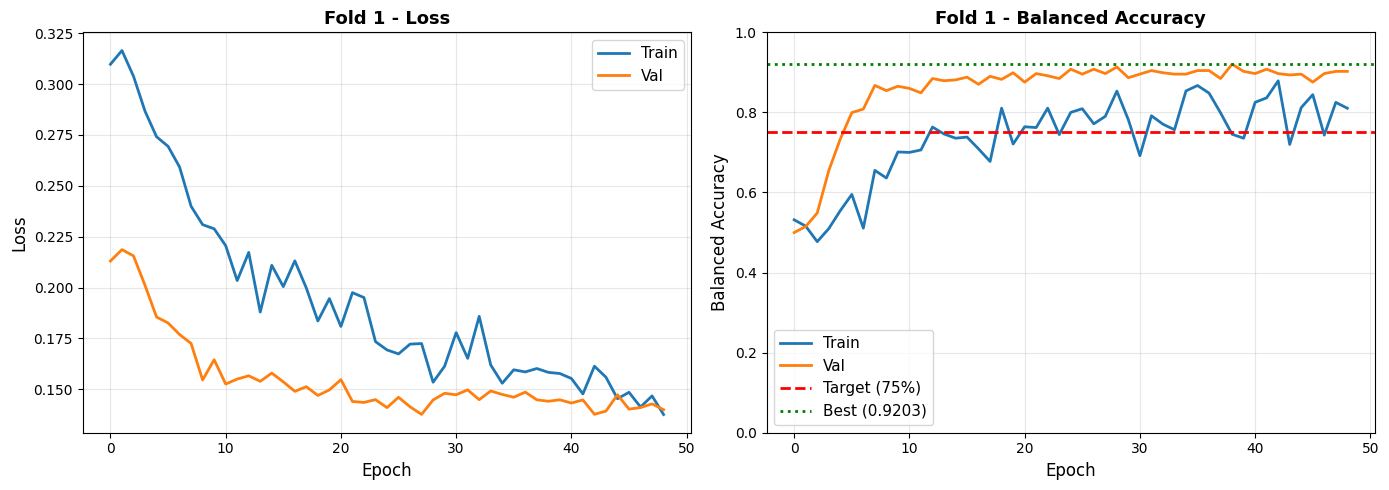

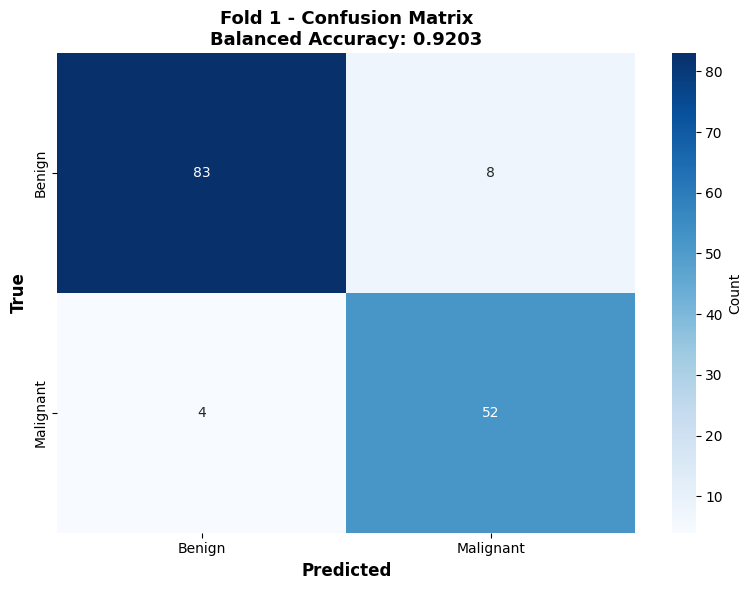

FOLD 1 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9540    0.9121    0.9326        91
   Malignant     0.8667    0.9286    0.8966        56

    accuracy                         0.9184       147
   macro avg     0.9103    0.9203    0.9146       147
weighted avg     0.9207    0.9184    0.9189       147


──────────────────────────────────────────────────────────────────────
FOLD 1 - SAMPLE PREDICTIONS
──────────────────────────────────────────────────────────────────────



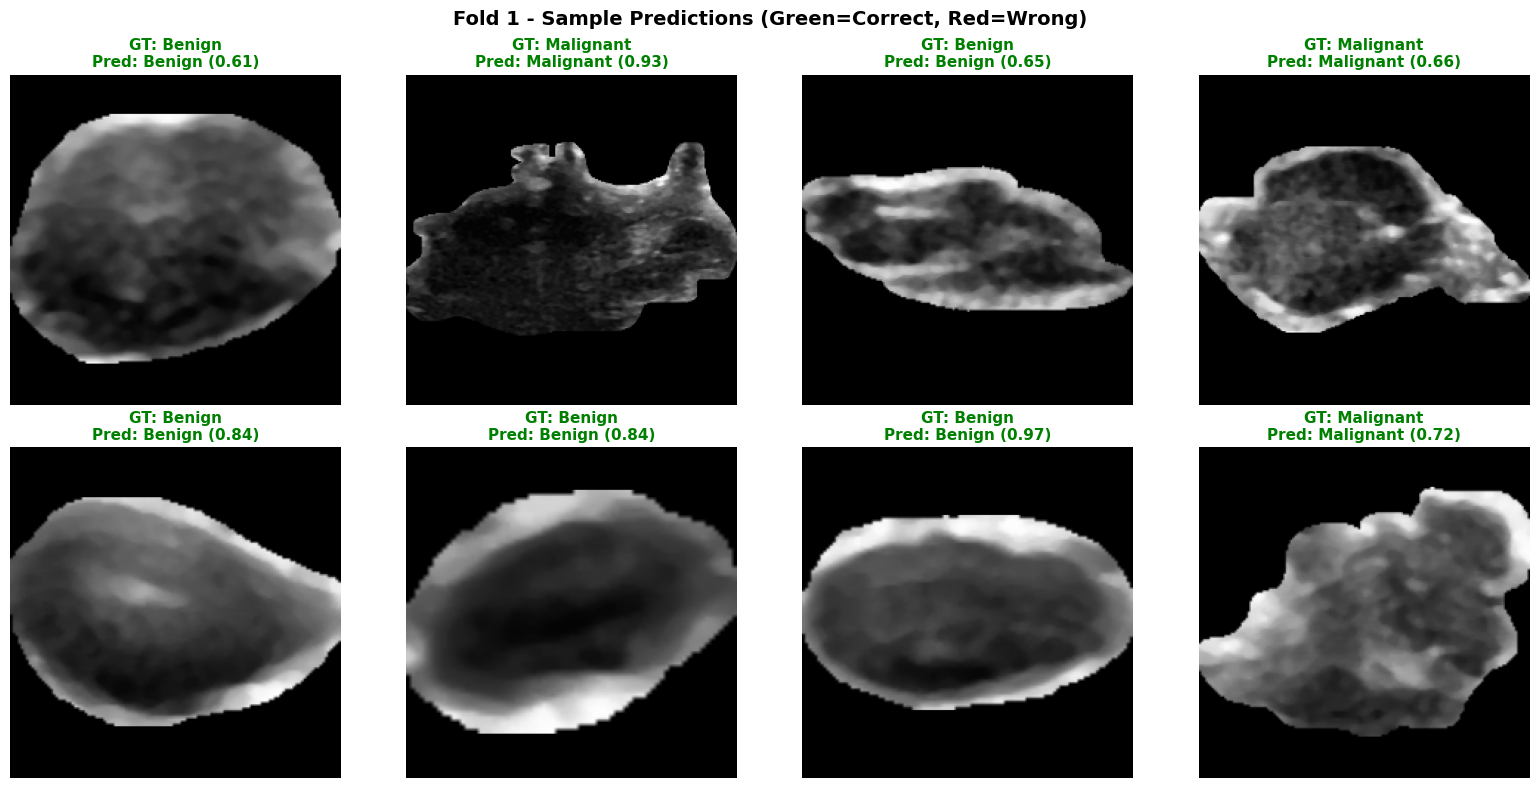


FOLD 2/5
Train: 539 patients, Val: 135 patients
Train samples: 645, Val samples: 189

✅ Class weights (fold 2): Benign=0.7828, Malignant=1.3841
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 0.0003

Important - num_epochs of training = ** 50 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 451 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.001
Gradient Centralization = On

Adaptive Gradient Clipping = Tr

Train:   0%|          | 0/41 [00:00<?, ?it/s]

params size saved
total param groups = 1
total params in groups = 369


Val:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch  1/50 | Train Loss: 0.2828 | Train Acc: 0.4995 | Val Loss: 0.1913 | Val Acc: 0.4464 
   💾 Model saved (no overfitting: val_loss 0.1913 < train_loss 0.2828)


...


** Ranger21 update: Warmdown starting now.  Current iteration = 1476....



Val:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch 36/50 | Train Loss: 0.1573 | Train Acc: 0.7710 | Val Loss: 0.1632 | Val Acc: 0.9154 ✅ TARGET!
Early stopping at epoch 36


✅ Loaded best model from epoch 26 (BA: 0.9192)


Val:   0%|          | 0/12 [00:00<?, ?it/s]


Fold 2 Results:
  Best Bal Acc: 0.9192 (epoch 26)
  Final Bal Acc: 0.9192
  Status: ✅ TARGET ACHIEVED

──────────────────────────────────────────────────────────────────────
FOLD 2 VISUALIZATIONS
──────────────────────────────────────────────────────────────────────



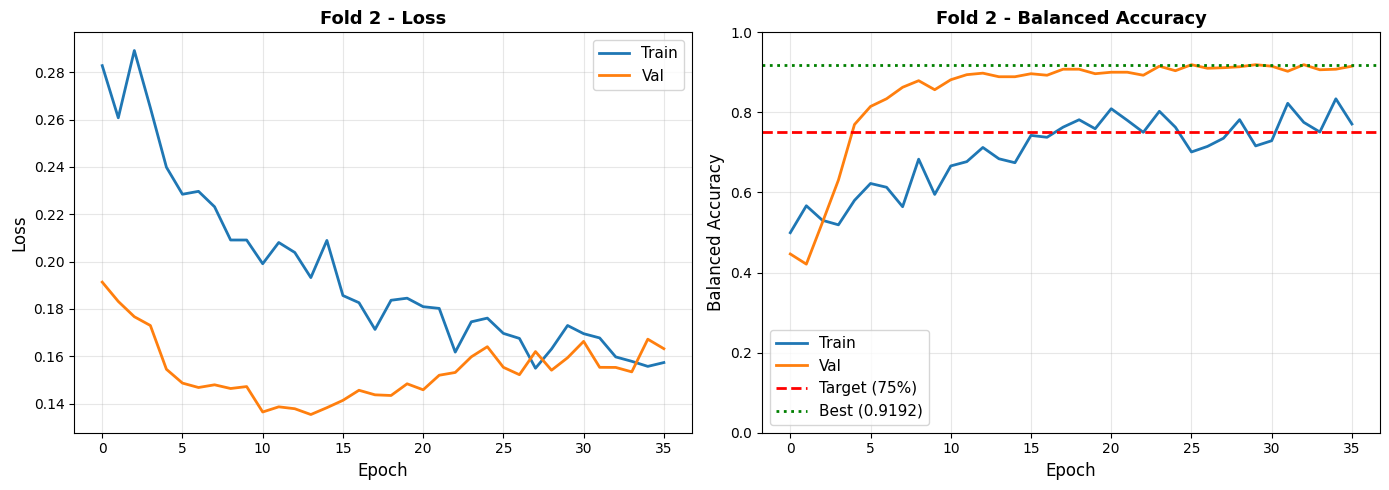

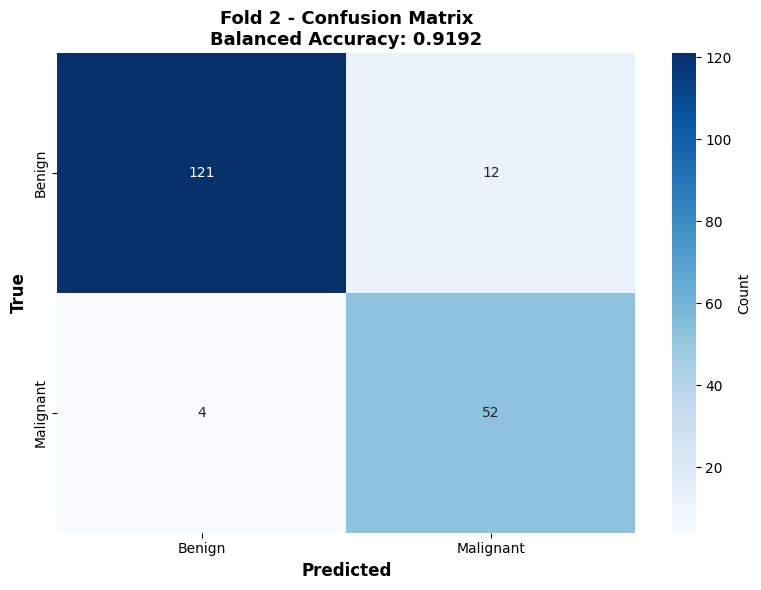

FOLD 2 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9680    0.9098    0.9380       133
   Malignant     0.8125    0.9286    0.8667        56

    accuracy                         0.9153       189
   macro avg     0.8902    0.9192    0.9023       189
weighted avg     0.9219    0.9153    0.9169       189


──────────────────────────────────────────────────────────────────────
FOLD 2 - SAMPLE PREDICTIONS
──────────────────────────────────────────────────────────────────────



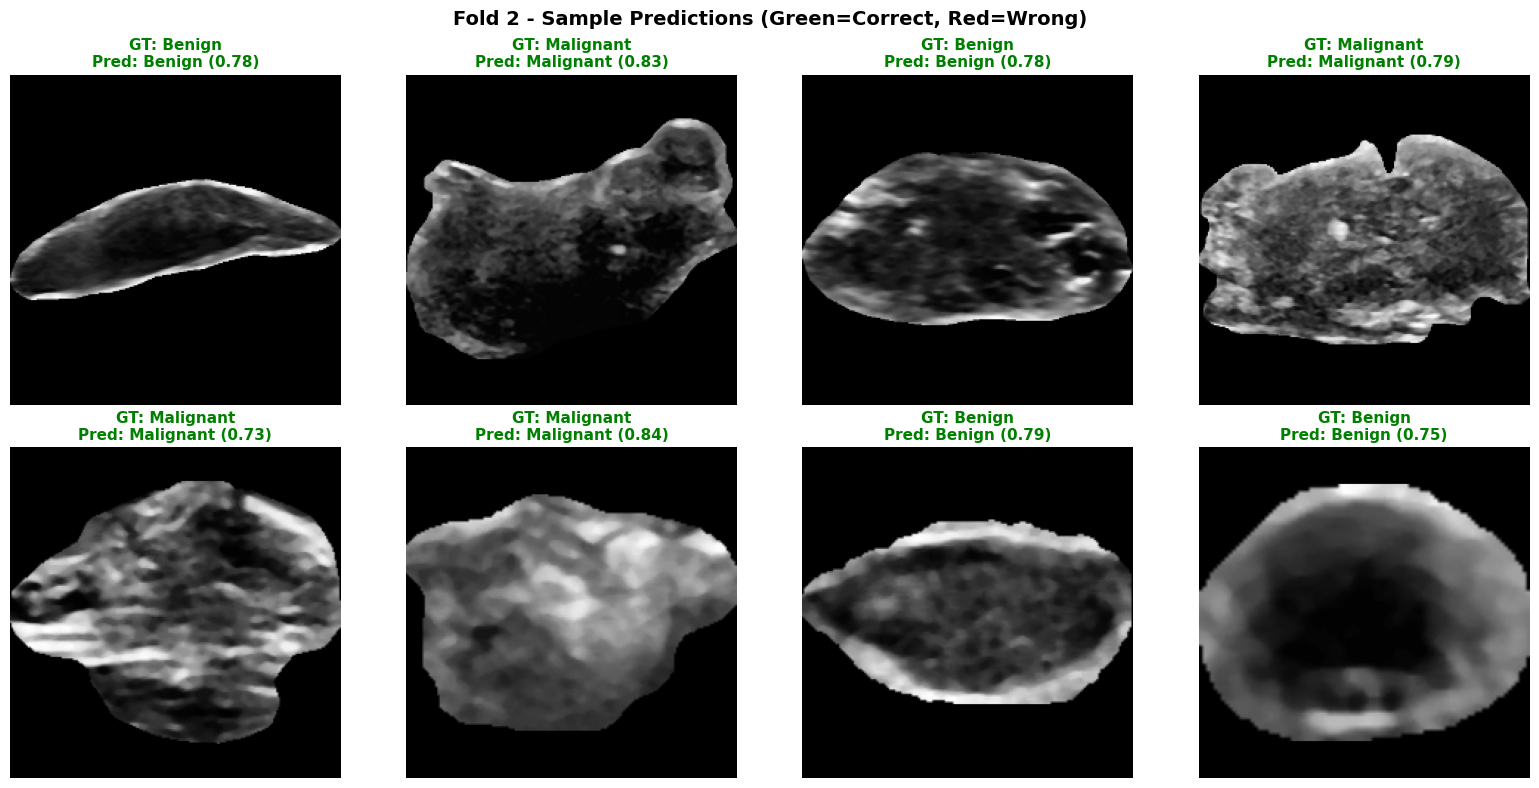


FOLD 3/5
Train: 539 patients, Val: 135 patients
Train samples: 679, Val samples: 155

✅ Class weights (fold 3): Benign=0.7511, Malignant=1.4956
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 0.0003

Important - num_epochs of training = ** 50 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 473 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.001
Gradient Centralization = On

Adaptive Gradient Clipping = Tr

Train:   0%|          | 0/43 [00:00<?, ?it/s]

params size saved
total param groups = 1
total params in groups = 369


Val:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch  1/50 | Train Loss: 0.2371 | Train Acc: 0.4630 | Val Loss: 0.1669 | Val Acc: 0.4839 
   💾 Model saved (no overfitting: val_loss 0.1669 < train_loss 0.2371)


...

Train:   0%|          | 0/43 [00:00<?, ?it/s]

Val:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 35/50 | Train Loss: 0.1262 | Train Acc: 0.7831 | Val Loss: 0.1172 | Val Acc: 0.8898 ✅ TARGET!
Early stopping at epoch 35


✅ Loaded best model from epoch 25 (BA: 0.9059)


Val:   0%|          | 0/10 [00:00<?, ?it/s]


Fold 3 Results:
  Best Bal Acc: 0.9059 (epoch 25)
  Final Bal Acc: 0.9059
  Status: ✅ TARGET ACHIEVED

──────────────────────────────────────────────────────────────────────
FOLD 3 VISUALIZATIONS
──────────────────────────────────────────────────────────────────────



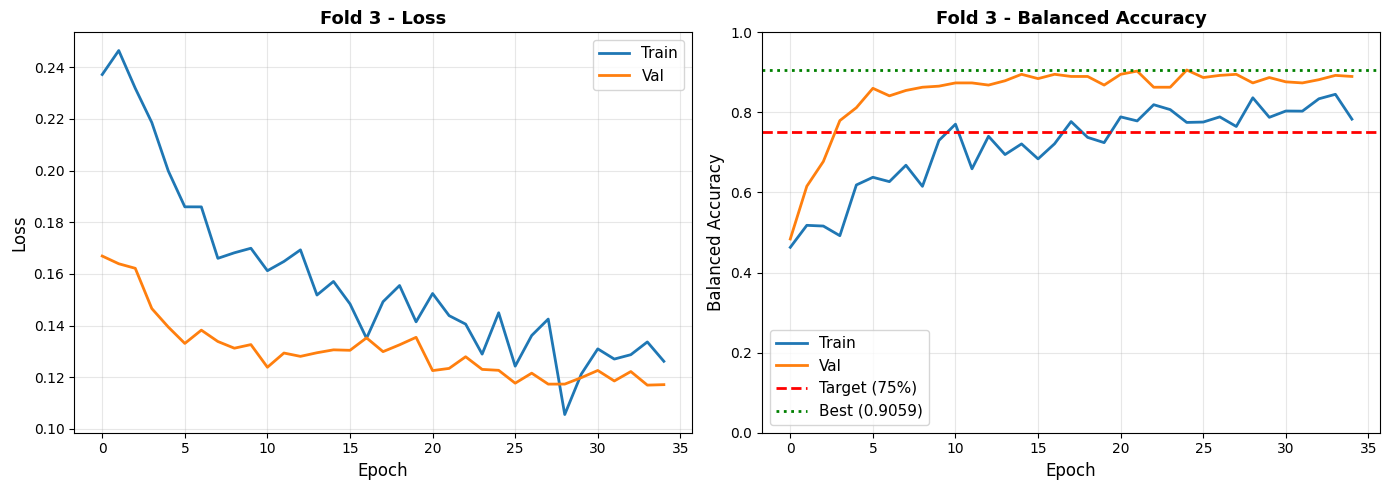

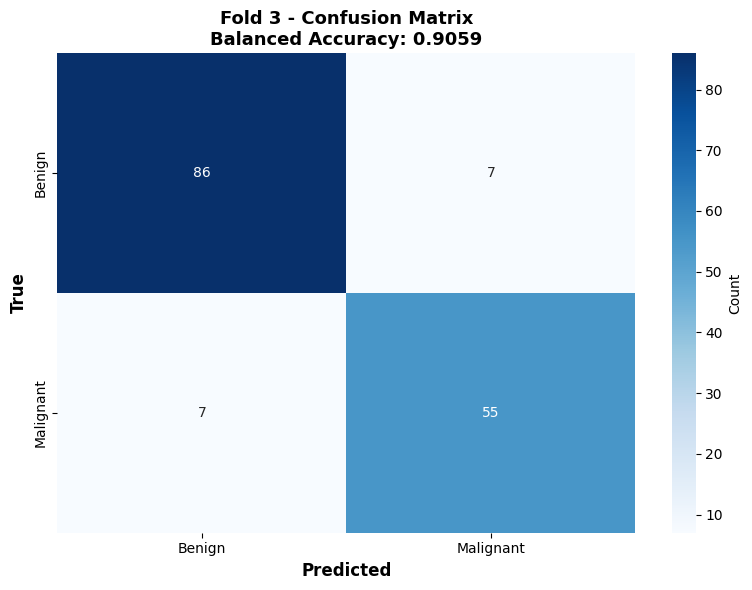

FOLD 3 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9247    0.9247    0.9247        93
   Malignant     0.8871    0.8871    0.8871        62

    accuracy                         0.9097       155
   macro avg     0.9059    0.9059    0.9059       155
weighted avg     0.9097    0.9097    0.9097       155


──────────────────────────────────────────────────────────────────────
FOLD 3 - SAMPLE PREDICTIONS
──────────────────────────────────────────────────────────────────────



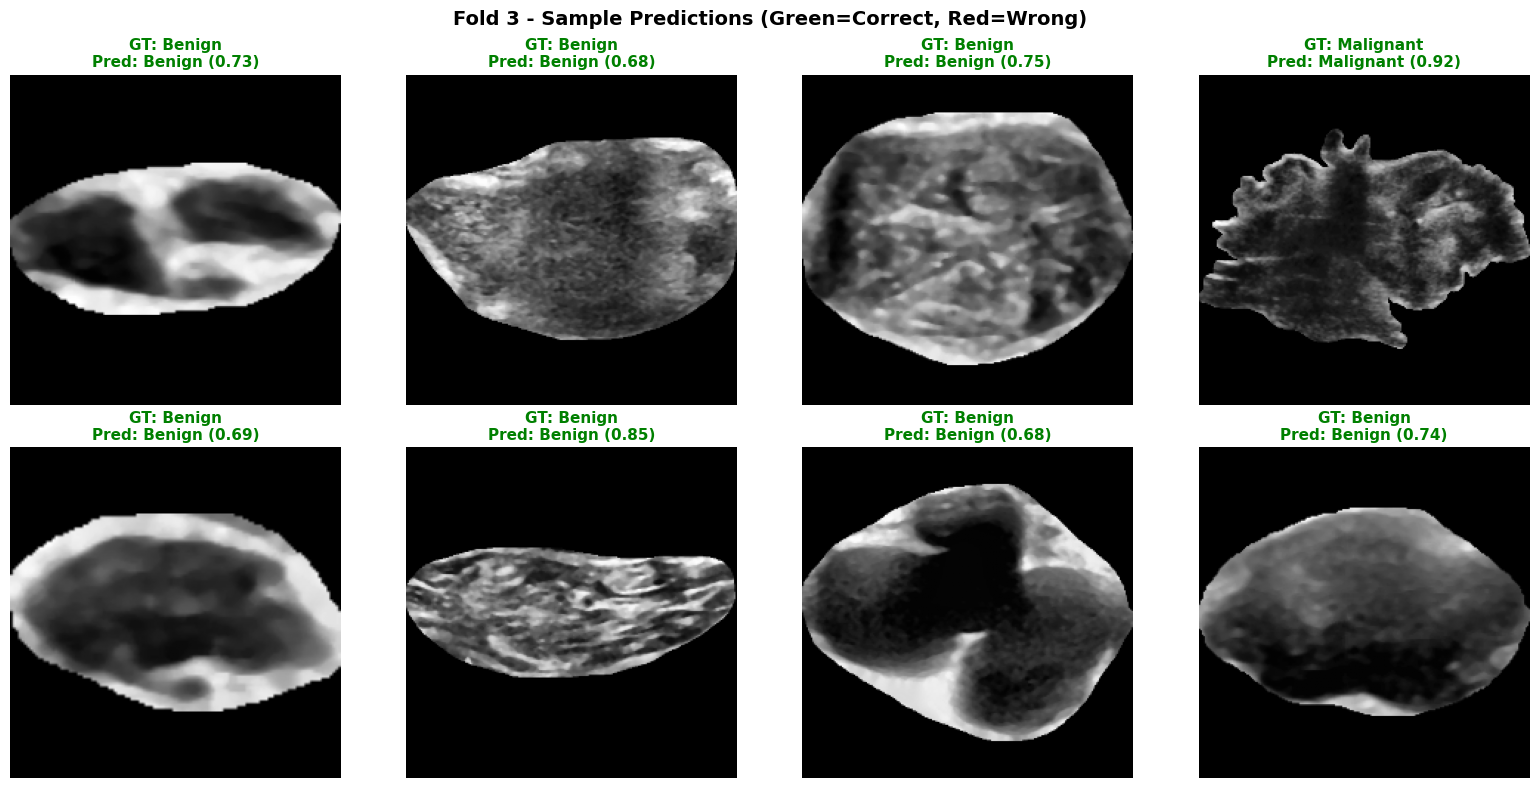


FOLD 4/5
Train: 539 patients, Val: 135 patients
Train samples: 675, Val samples: 159

✅ Class weights (fold 4): Benign=0.7741, Malignant=1.4121
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 0.0003

Important - num_epochs of training = ** 50 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 473 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.001
Gradient Centralization = On

Adaptive Gradient Clipping = Tr

Train:   0%|          | 0/43 [00:00<?, ?it/s]

params size saved
total param groups = 1
total params in groups = 369


Val:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch  1/50 | Train Loss: 0.2673 | Train Acc: 0.5139 | Val Loss: 0.1668 | Val Acc: 0.5046 
   💾 Model saved (no overfitting: val_loss 0.1668 < train_loss 0.2673)


...

Train:   0%|          | 0/43 [00:00<?, ?it/s]

Val:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 28/50 | Train Loss: 0.1491 | Train Acc: 0.8348 | Val Loss: 0.1229 | Val Acc: 0.9079 ✅ TARGET!
Early stopping at epoch 28


✅ Loaded best model from epoch 18 (BA: 0.9087)


Val:   0%|          | 0/10 [00:00<?, ?it/s]


Fold 4 Results:
  Best Bal Acc: 0.9087 (epoch 18)
  Final Bal Acc: 0.9087
  Status: ✅ TARGET ACHIEVED

──────────────────────────────────────────────────────────────────────
FOLD 4 VISUALIZATIONS
──────────────────────────────────────────────────────────────────────



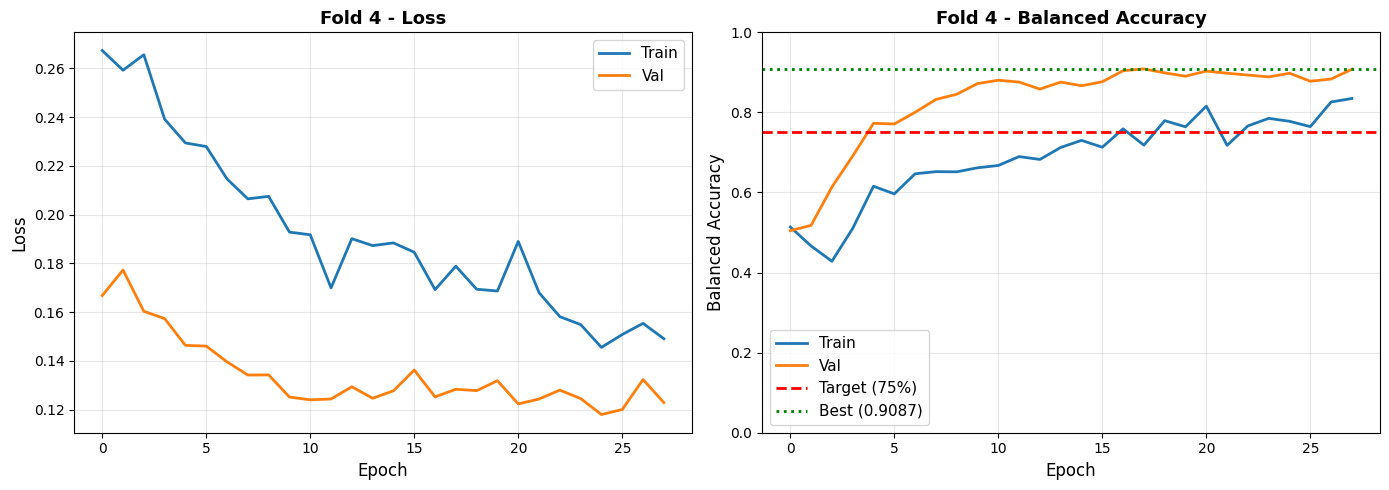

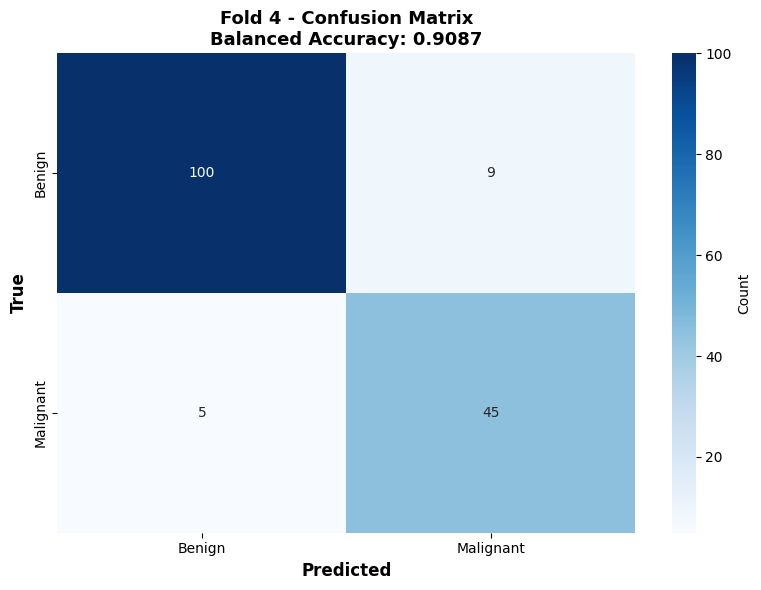

FOLD 4 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9524    0.9174    0.9346       109
   Malignant     0.8333    0.9000    0.8654        50

    accuracy                         0.9119       159
   macro avg     0.8929    0.9087    0.9000       159
weighted avg     0.9149    0.9119    0.9128       159


──────────────────────────────────────────────────────────────────────
FOLD 4 - SAMPLE PREDICTIONS
──────────────────────────────────────────────────────────────────────



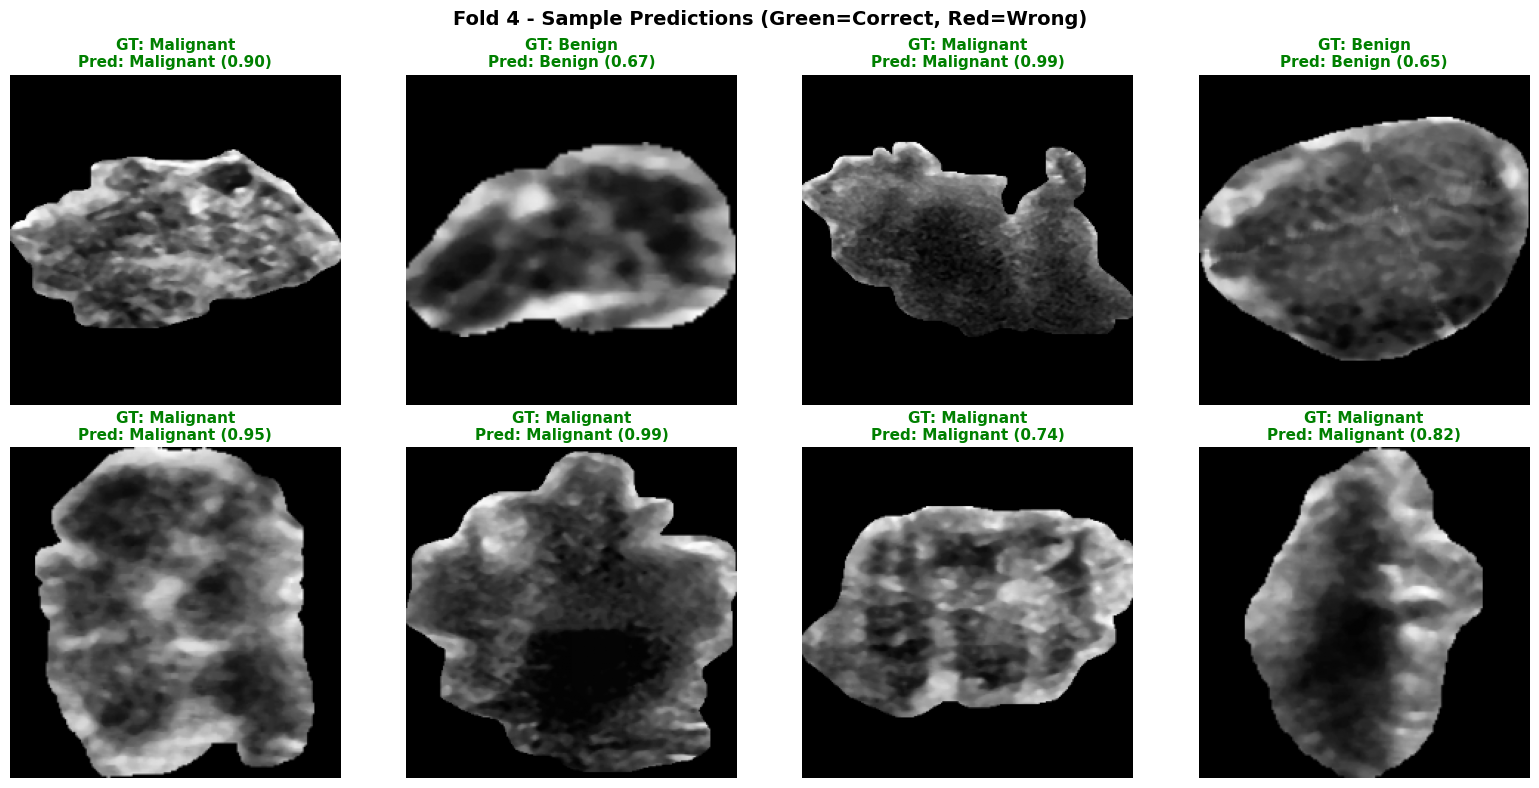


FOLD 5/5
Train: 540 patients, Val: 134 patients
Train samples: 650, Val samples: 184

✅ Class weights (fold 5): Benign=0.7629, Malignant=1.4509
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 0.0003

Important - num_epochs of training = ** 50 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 451 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.001
Gradient Centralization = On

Adaptive Gradient Clipping = Tr

Train:   0%|          | 0/41 [00:00<?, ?it/s]

params size saved
total param groups = 1
total params in groups = 369


Val:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch  1/50 | Train Loss: 0.3107 | Train Acc: 0.4867 | Val Loss: 0.1802 | Val Acc: 0.5814 
   💾 Model saved (no overfitting: val_loss 0.1802 < train_loss 0.3107)


...

Train:   0%|          | 0/41 [00:00<?, ?it/s]

Val:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch 34/50 | Train Loss: 0.1620 | Train Acc: 0.7671 | Val Loss: 0.1377 | Val Acc: 0.8831 ✅ TARGET!
Early stopping at epoch 34


✅ Loaded best model from epoch 24 (BA: 0.8992)


Val:   0%|          | 0/12 [00:00<?, ?it/s]


Fold 5 Results:
  Best Bal Acc: 0.8992 (epoch 24)
  Final Bal Acc: 0.8992
  Status: ✅ TARGET ACHIEVED

──────────────────────────────────────────────────────────────────────
FOLD 5 VISUALIZATIONS
──────────────────────────────────────────────────────────────────────



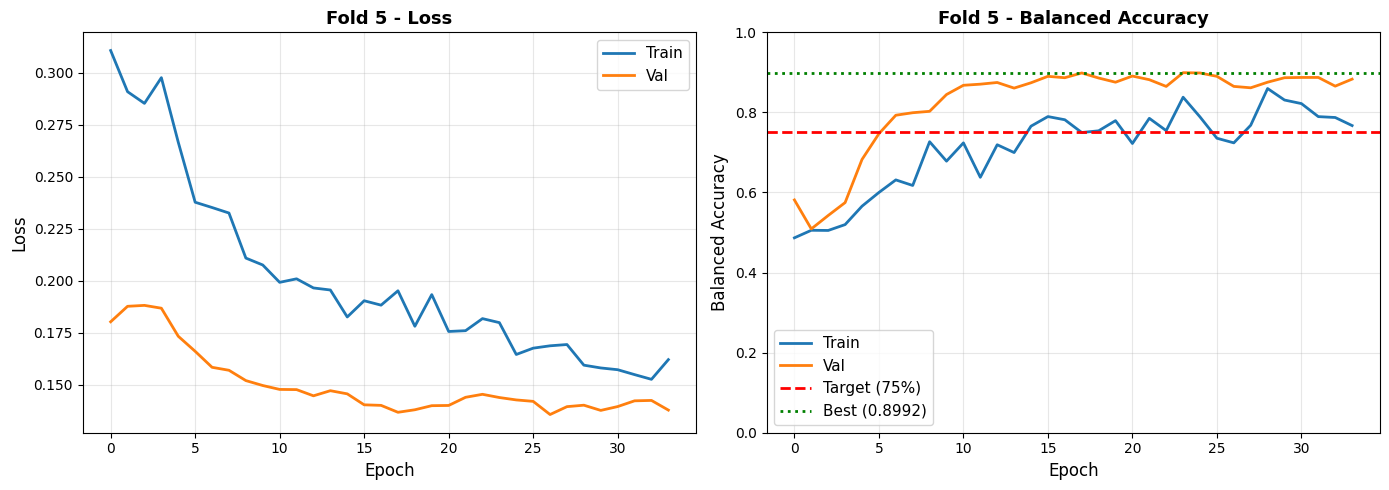

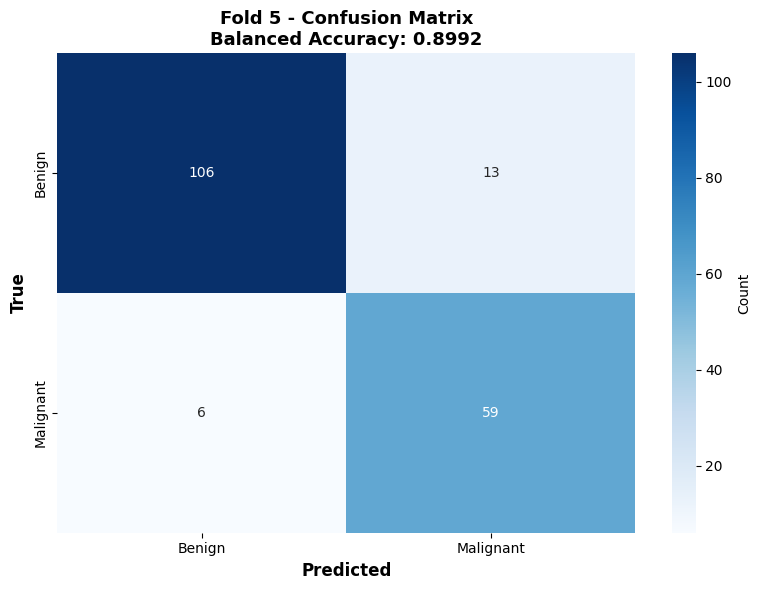

FOLD 5 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9464    0.8908    0.9177       119
   Malignant     0.8194    0.9077    0.8613        65

    accuracy                         0.8967       184
   macro avg     0.8829    0.8992    0.8895       184
weighted avg     0.9016    0.8967    0.8978       184


──────────────────────────────────────────────────────────────────────
FOLD 5 - SAMPLE PREDICTIONS
──────────────────────────────────────────────────────────────────────



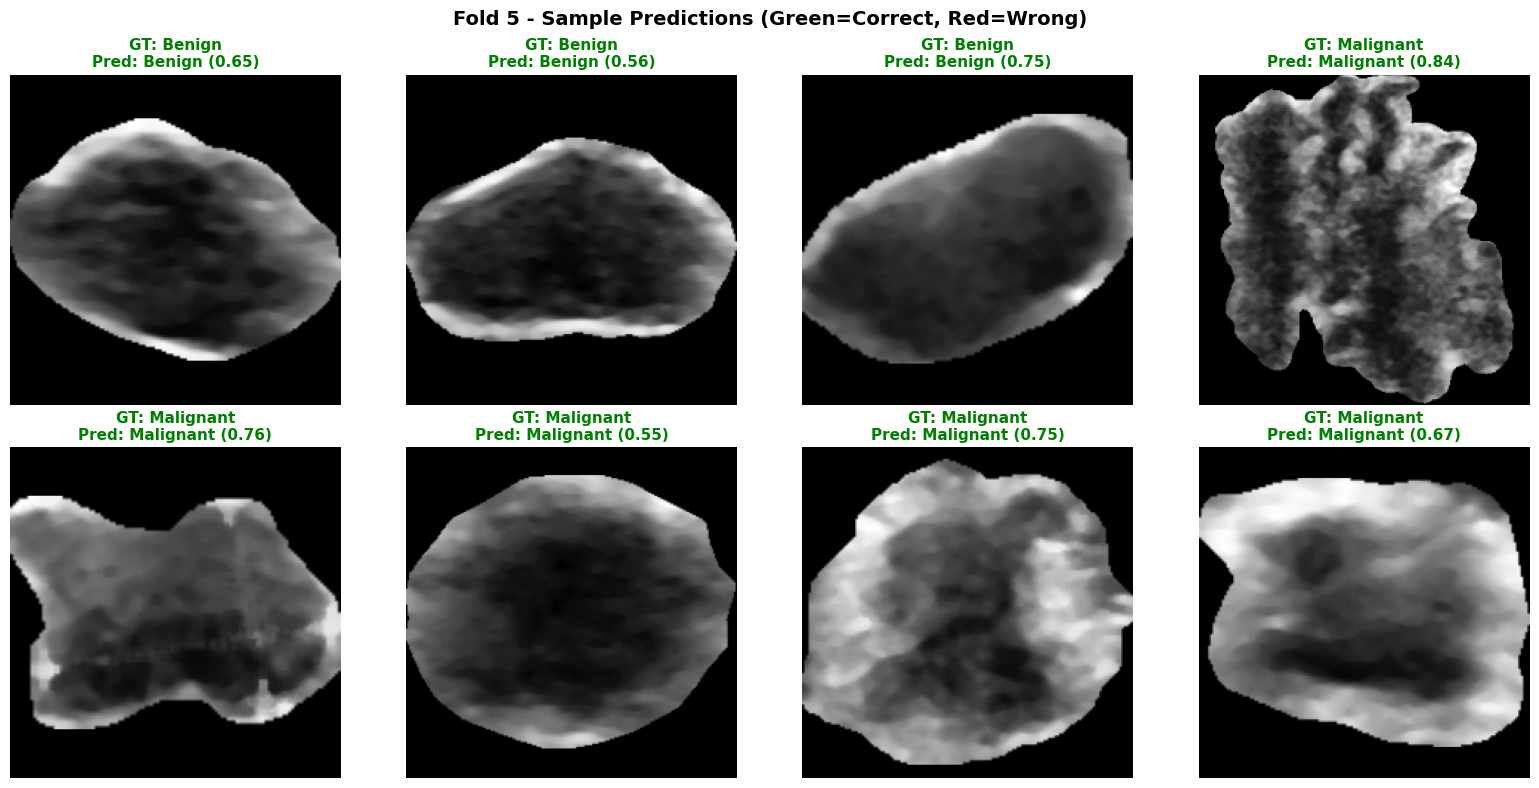



✅ 5-FOLD CROSS VALIDATION COMPLETE

 fold  best_bal_acc  final_bal_acc  best_epoch
    1      0.920330       0.920330          39
    2      0.919173       0.919173          26
    3      0.905914       0.905914          25
    4      0.908716       0.908716          18
    5      0.899224       0.899224          24

SUMMARY
Mean Best Bal Acc: 0.9107 ± 0.0080
Mean Final Bal Acc: 0.9107 ± 0.0080
Overall Target Status: ✅ ACHIEVED
Folds with Target (>75%): 5/5


In [13]:

major_labels = np.array([p['major_label'] for p in train_data])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_results = {
    'fold': [],
    'best_bal_acc': [],
    'final_bal_acc': [],
    'best_epoch': []
}

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(np.arange(len(train_data)), major_labels)):
    print(f"\n{'='*70}")
    print(f"FOLD {fold_idx + 1}/5")
    print(f"{'='*70}")
    
    # Split
    train_patients = [train_data[i] for i in train_idx]
    val_patients = [train_data[i] for i in val_idx]
    
    print(f"Train: {len(train_patients)} patients, Val: {len(val_patients)} patients")
    
    train_dataset = LesionClassificationDataset(train_patients, augment=True)
    val_dataset = LesionClassificationDataset(val_patients, augment=False)
    
    print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}\n")
    
    train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)
    
    from sklearn.utils.class_weight import compute_class_weight
    train_labels_np = np.array([s['label'] for p in train_patients for s in p['samples']])
    class_weights_np = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels_np)
    class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=Config.DEVICE)
    print(f"✅ Class weights (fold {fold_idx+1}): Benign={class_weights[0]:.4f}, Malignant={class_weights[1]:.4f}")
    
    model = EfficientNetWithROIAwareCBAM(
        num_classes=Config.NUM_CLASSES,
        dropout=Config.DROPOUT
    ).to(Config.DEVICE)
    
    # Optimizer
    optimizer = Ranger21(
        model.parameters(),
        lr=Config.LEARNING_RATE,
        weight_decay=Config.WEIGHT_DECAY,
        num_epochs=Config.NUM_EPOCHS,
        num_batches_per_epoch=len(train_loader)
    )
    
    criterion = CombinedLossV2(
        class_weights=class_weights,
        alpha=0.85,
        gamma=Config.FOCAL_GAMMA,
        label_smoothing=Config.LABEL_SMOOTHING
    )
    
    from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, LinearLR, SequentialLR
    
    warmup_epochs = 5
    warmup_batches = warmup_epochs * len(train_loader)
    warmup_scheduler = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_batches)
    
    main_scheduler = CosineAnnealingWarmRestarts(
        optimizer, 
        T_0=10, 
        T_mult=2, 
        eta_min=1e-6
    )
    
    scheduler = SequentialLR(
        optimizer,
        schedulers=[warmup_scheduler, main_scheduler],
        milestones=[warmup_batches]
    )
    
    history = {
        'train_loss': [], 'val_loss': [],
        'train_bal_acc': [], 'val_bal_acc': []
    }
    
    best_bal_acc = 0.0
    best_epoch = 0
    patience_counter = 0
    
    print(f"🚀 Training Fold {fold_idx + 1}...\n")
    
    for epoch in range(Config.NUM_EPOCHS):
        train_loss, train_bal_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, Config.DEVICE, 
            scheduler=scheduler,
            use_mixup=Config.MIXUP_ENABLED,
            mixup_alpha=Config.MIXUP_ALPHA
        )
        
        val_loss, val_bal_acc, val_preds, val_labels = validate(
            model, val_loader, criterion, Config.DEVICE
        )
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_bal_acc'].append(train_bal_acc)
        history['val_bal_acc'].append(val_bal_acc)
        
        target_status = "✅ TARGET!" if val_bal_acc >= 0.75 else ""
        print(f"Epoch {epoch+1:2d}/{Config.NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Train Acc: {train_bal_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_bal_acc:.4f} {target_status}")
        
        no_overfitting = val_loss < train_loss
        if val_bal_acc > best_bal_acc and no_overfitting:
            best_bal_acc = val_bal_acc
            best_epoch = epoch
            torch.save({
                'model_state_dict': model.state_dict(),
                'fold': fold_idx,
                'epoch': epoch,
                'balanced_accuracy': best_bal_acc,
                'train_loss': train_loss,
                'val_loss': val_loss
            }, f'best_classification_fold{fold_idx}.pt')
            patience_counter = 0
            print(f"   💾 Model saved (no overfitting: val_loss {val_loss:.4f} < train_loss {train_loss:.4f})")
        else:
            patience_counter += 1
            if val_bal_acc > best_bal_acc:
                print(f"   ⚠️  Better acc ({val_bal_acc:.4f}) but overfitting detected (val_loss {val_loss:.4f} >= train_loss {train_loss:.4f}) - not saved")
        
        if patience_counter >= Config.PATIENCE:
            print(f"Early stopping at epoch {epoch+1}\n")
            break
        
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    
    best_model_path = f'best_classification_fold{fold_idx}.pt'
    if os.path.exists(best_model_path):
        checkpoint = torch.load(best_model_path, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"\n✅ Loaded best model from epoch {checkpoint['epoch']+1} (BA: {checkpoint['balanced_accuracy']:.4f})")
    else:
        print(f"\n⚠️ Best model file not found, using current model")
    
    _, final_bal_acc, final_preds, final_labels = validate(
        model, val_loader, criterion, Config.DEVICE
    )
    
    fold_results['fold'].append(fold_idx + 1)
    fold_results['best_bal_acc'].append(best_bal_acc)
    fold_results['final_bal_acc'].append(final_bal_acc)
    fold_results['best_epoch'].append(best_epoch + 1)
    
    print(f"\nFold {fold_idx + 1} Results:")
    print(f"  Best Bal Acc: {best_bal_acc:.4f} (epoch {best_epoch + 1})")
    print(f"  Final Bal Acc: {final_bal_acc:.4f}")
    print(f"  Status: {'✅ TARGET ACHIEVED' if best_bal_acc >= 0.75 else '❌ Below target'}")
    

    print(f"\n{'─'*70}")
    print(f"FOLD {fold_idx + 1} VISUALIZATIONS")
    print(f"{'─'*70}\n")
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title(f'Fold {fold_idx + 1} - Loss', fontsize=13, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(history['train_bal_acc'], label='Train', linewidth=2)
    axes[1].plot(history['val_bal_acc'], label='Val', linewidth=2)
    axes[1].axhline(y=0.75, color='r', linestyle='--', label='Target (75%)', linewidth=2)
    axes[1].axhline(y=best_bal_acc, color='g', linestyle=':', label=f'Best ({best_bal_acc:.4f})', linewidth=2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Balanced Accuracy', fontsize=12)
    axes[1].set_title(f'Fold {fold_idx + 1} - Balanced Accuracy', fontsize=13, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim([0, 1.0])
    
    plt.tight_layout()
    plt.show()
    
    cm = confusion_matrix(final_labels, final_preds)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'],
                cbar_kws={'label': 'Count'},
                ax=ax)
    ax.set_xlabel('Predicted', fontsize=12, fontweight='bold')
    ax.set_ylabel('True', fontsize=12, fontweight='bold')
    ax.set_title(f'Fold {fold_idx + 1} - Confusion Matrix\nBalanced Accuracy: {final_bal_acc:.4f}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print(f"{'='*70}")
    print(f"FOLD {fold_idx + 1} - CLASSIFICATION REPORT")
    print(f"{'='*70}")
    print(classification_report(final_labels, final_preds, 
                               target_names=['Benign', 'Malignant'], digits=4))
    
    print(f"\n{'─'*70}")
    print(f"FOLD {fold_idx + 1} - SAMPLE PREDICTIONS")
    print(f"{'─'*70}\n")
    
    n_samples = 8
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    
    indices = np.random.choice(len(val_dataset), n_samples, replace=False)
    
    model.eval()
    with torch.no_grad():
        for i, idx in enumerate(indices):
            sample = val_dataset[idx]
            img = sample['image'].unsqueeze(0).to(Config.DEVICE)
            label = sample['label'].item()
            
            logits = model(img)
            probs = F.softmax(logits, dim=1)
            pred = torch.argmax(logits, dim=1).item()
            conf = probs[0, pred].item()
            
            img_display = sample['image'][0].numpy()  # First channel
            img_display = (img_display - img_display.min()) / (img_display.max() - img_display.min() + 1e-8)
            
            axes[i].imshow(img_display, cmap='gray')
            
            label_name = 'Benign' if label == 0 else 'Malignant'
            pred_name = 'Benign' if pred == 0 else 'Malignant'
            color = 'green' if label == pred else 'red'
            
            axes[i].set_title(f"GT: {label_name}\nPred: {pred_name} ({conf:.2f})", color=color, fontsize=11, fontweight='bold')
            axes[i].axis('off')
    
    plt.suptitle(f'Fold {fold_idx + 1} - Sample Predictions (Green=Correct, Red=Wrong)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print(f"\n\n{'='*70}")
print("✅ 5-FOLD CROSS VALIDATION COMPLETE")
print(f"{'='*70}\n")

import pandas as pd
summary_df = pd.DataFrame(fold_results)
print(summary_df.to_string(index=False))

print(f"\n{'='*70}")
print("SUMMARY")
print(f"{'='*70}")
print(f"Mean Best Bal Acc: {np.mean(fold_results['best_bal_acc']):.4f} ± {np.std(fold_results['best_bal_acc']):.4f}")

print(f"Mean Final Bal Acc: {np.mean(fold_results['final_bal_acc']):.4f} ± {np.std(fold_results['final_bal_acc']):.4f}")
print(f"Overall Target Status: {'✅ ACHIEVED' if np.mean(fold_results['best_bal_acc']) >= 0.75 else '❌ NOT ACHIEVED'}")
print(f"Folds with Target (>75%): {sum(1 for x in fold_results['best_bal_acc'] if x >= 0.75)}/5")

## Results



COMPREHENSIVE FOLD COMPARISON



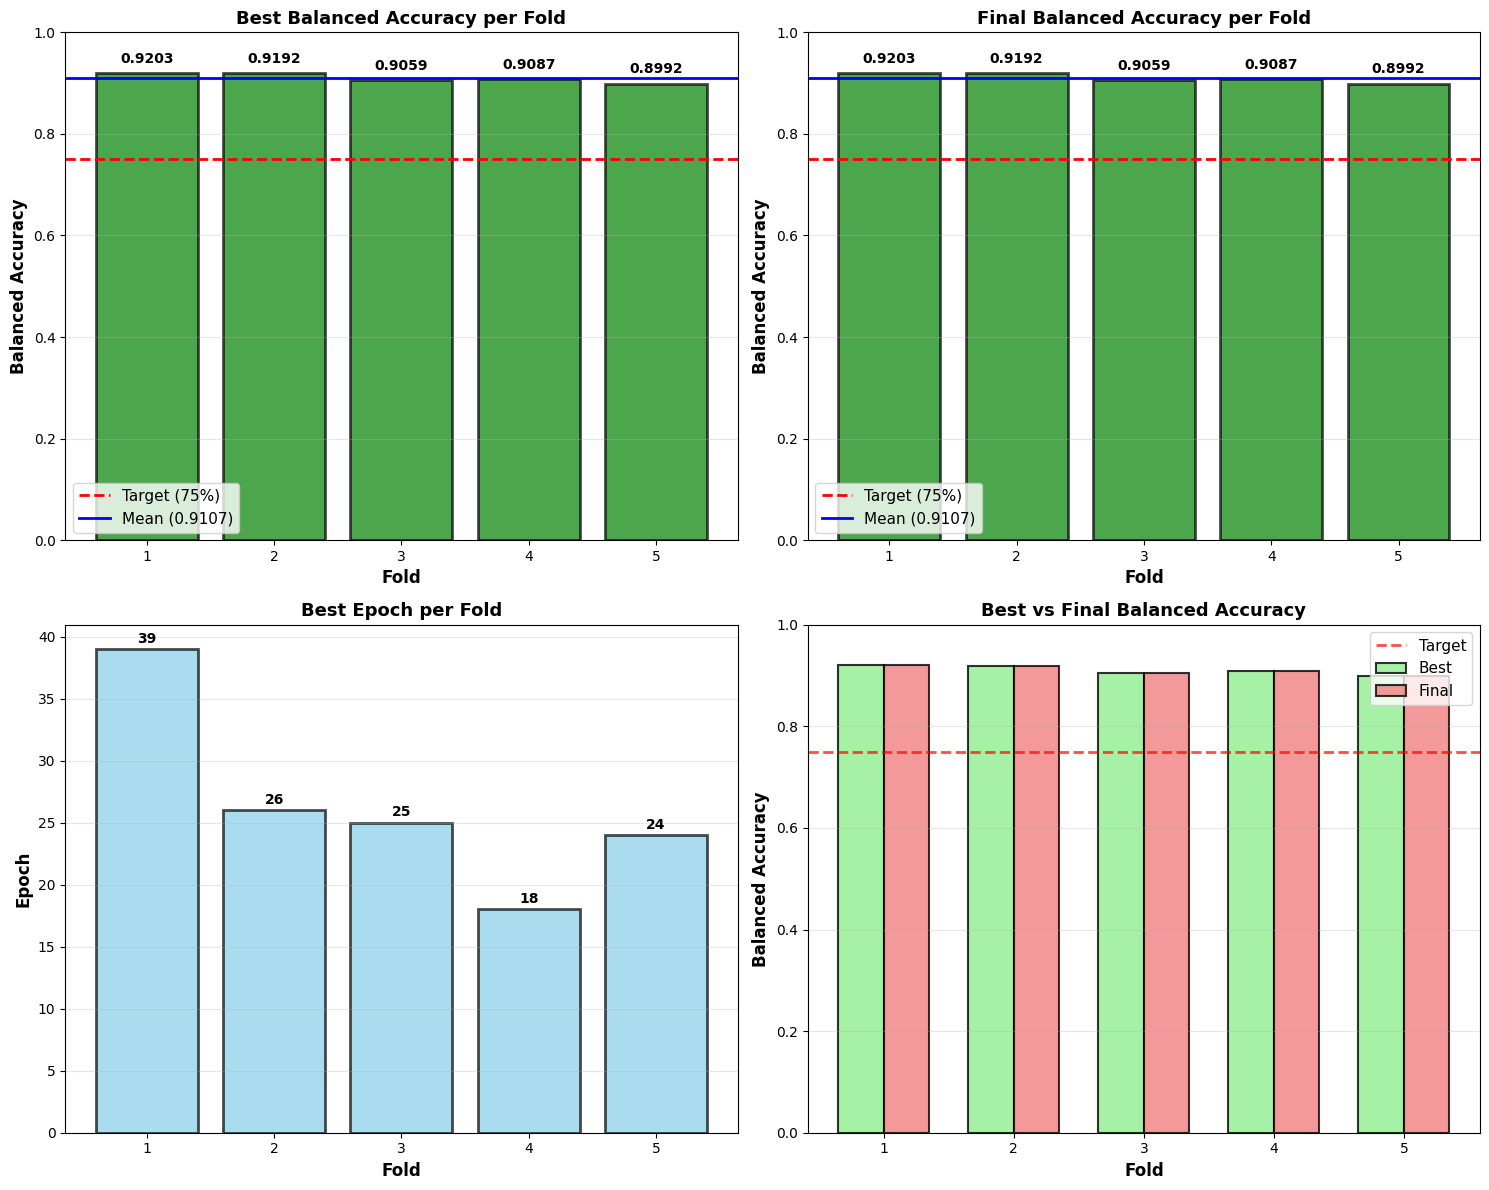

DETAILED FOLD RESULTS
 Fold Best Bal Acc Final Bal Acc  Best Epoch     Status
    1       0.9203        0.9203          39 ✅ ACHIEVED
    2       0.9192        0.9192          26 ✅ ACHIEVED
    3       0.9059        0.9059          25 ✅ ACHIEVED
    4       0.9087        0.9087          18 ✅ ACHIEVED
    5       0.8992        0.8992          24 ✅ ACHIEVED

OVERALL STATISTICS
Mean Best Bal Acc:     0.9107 ± 0.0080
Mean Final Bal Acc:    0.9107 ± 0.0080
Mean Best Epoch:       26.4 ± 6.9
Folds with Target:     5/5
Overall Status:        ✅ ACHIEVED

DISTRIBUTION ANALYSIS
Best Bal Acc - Min: 0.8992, Max: 0.9203, Range: 0.0211
Final Bal Acc - Min: 0.8992, Max: 0.9203, Range: 0.0211


In [14]:
print(f"\n\n{'='*70}")
print("COMPREHENSIVE FOLD COMPARISON")
print(f"{'='*70}\n")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

ax = axes[0, 0]
folds = fold_results['fold']
best_accs = fold_results['best_bal_acc']
colors = ['green' if acc >= 0.75 else 'orange' for acc in best_accs]
bars = ax.bar(folds, best_accs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.axhline(y=0.75, color='r', linestyle='--', linewidth=2, label='Target (75%)')
ax.axhline(y=np.mean(best_accs), color='blue', linestyle='-', linewidth=2, label=f'Mean ({np.mean(best_accs):.4f})')
ax.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax.set_ylabel('Balanced Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Best Balanced Accuracy per Fold', fontsize=13, fontweight='bold')
ax.set_ylim([0, 1.0])
ax.set_xticks(folds)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
for i, (fold, acc) in enumerate(zip(folds, best_accs)):
    ax.text(fold, acc + 0.02, f'{acc:.4f}', ha='center', fontsize=10, fontweight='bold')

ax = axes[0, 1]
final_accs = fold_results['final_bal_acc']
colors = ['green' if acc >= 0.75 else 'orange' for acc in final_accs]
bars = ax.bar(folds, final_accs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.axhline(y=0.75, color='r', linestyle='--', linewidth=2, label='Target (75%)')
ax.axhline(y=np.mean(final_accs), color='blue', linestyle='-', linewidth=2, label=f'Mean ({np.mean(final_accs):.4f})')
ax.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax.set_ylabel('Balanced Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Final Balanced Accuracy per Fold', fontsize=13, fontweight='bold')
ax.set_ylim([0, 1.0])
ax.set_xticks(folds)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
for i, (fold, acc) in enumerate(zip(folds, final_accs)):
    ax.text(fold, acc + 0.02, f'{acc:.4f}', ha='center', fontsize=10, fontweight='bold')

ax = axes[1, 0]
best_epochs = fold_results['best_epoch']
ax.bar(folds, best_epochs, color='skyblue', alpha=0.7, edgecolor='black', linewidth=2)
ax.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax.set_ylabel('Epoch', fontsize=12, fontweight='bold')
ax.set_title('Best Epoch per Fold', fontsize=13, fontweight='bold')
ax.set_xticks(folds)
ax.grid(True, alpha=0.3, axis='y')
for fold, epoch in zip(folds, best_epochs):
    ax.text(fold, epoch + 0.5, f'{int(epoch)}', ha='center', fontsize=10, fontweight='bold')

ax = axes[1, 1]
x = np.arange(len(folds))
width = 0.35
ax.bar(x - width/2, best_accs, width, label='Best', color='lightgreen', alpha=0.8, edgecolor='black', linewidth=1.5)
ax.bar(x + width/2, final_accs, width, label='Final', color='lightcoral', alpha=0.8, edgecolor='black', linewidth=1.5)
ax.axhline(y=0.75, color='r', linestyle='--', linewidth=2, alpha=0.7, label='Target')
ax.set_xlabel('Fold', fontsize=12, fontweight='bold')
ax.set_ylabel('Balanced Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Best vs Final Balanced Accuracy', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(folds)
ax.set_ylim([0, 1.0])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f"{'='*80}")
print("DETAILED FOLD RESULTS")
print(f"{'='*80}")
summary_table = pd.DataFrame({
    'Fold': fold_results['fold'],
    'Best Bal Acc': [f"{acc:.4f}" for acc in fold_results['best_bal_acc']],
    'Final Bal Acc': [f"{acc:.4f}" for acc in fold_results['final_bal_acc']],
    'Best Epoch': fold_results['best_epoch'],
    'Status': ['✅ ACHIEVED' if acc >= 0.75 else '❌ NOT ACHIEVED' for acc in fold_results['best_bal_acc']]
})
print(summary_table.to_string(index=False))

print(f"\n{'='*80}")
print("OVERALL STATISTICS")
print(f"{'='*80}")
print(f"Mean Best Bal Acc:     {np.mean(fold_results['best_bal_acc']):.4f} ± {np.std(fold_results['best_bal_acc']):.4f}")
print(f"Mean Final Bal Acc:    {np.mean(fold_results['final_bal_acc']):.4f} ± {np.std(fold_results['final_bal_acc']):.4f}")
print(f"Mean Best Epoch:       {np.mean(fold_results['best_epoch']):.1f} ± {np.std(fold_results['best_epoch']):.1f}")
print(f"Folds with Target:     {sum(1 for x in fold_results['best_bal_acc'] if x >= 0.75)}/5")
print(f"Overall Status:        {'✅ ACHIEVED' if np.mean(fold_results['best_bal_acc']) >= 0.75 else '❌ NOT ACHIEVED'}")

print(f"\n{'='*80}")
print("DISTRIBUTION ANALYSIS")
print(f"{'='*80}")
print(f"Best Bal Acc - Min: {np.min(fold_results['best_bal_acc']):.4f}, Max: {np.max(fold_results['best_bal_acc']):.4f}, Range: {np.max(fold_results['best_bal_acc']) - np.min(fold_results['best_bal_acc']):.4f}")
print(f"Final Bal Acc - Min: {np.min(fold_results['final_bal_acc']):.4f}, Max: {np.max(fold_results['final_bal_acc']):.4f}, Range: {np.max(fold_results['final_bal_acc']) - np.min(fold_results['final_bal_acc']):.4f}")

## Visualization: Sample Predictions

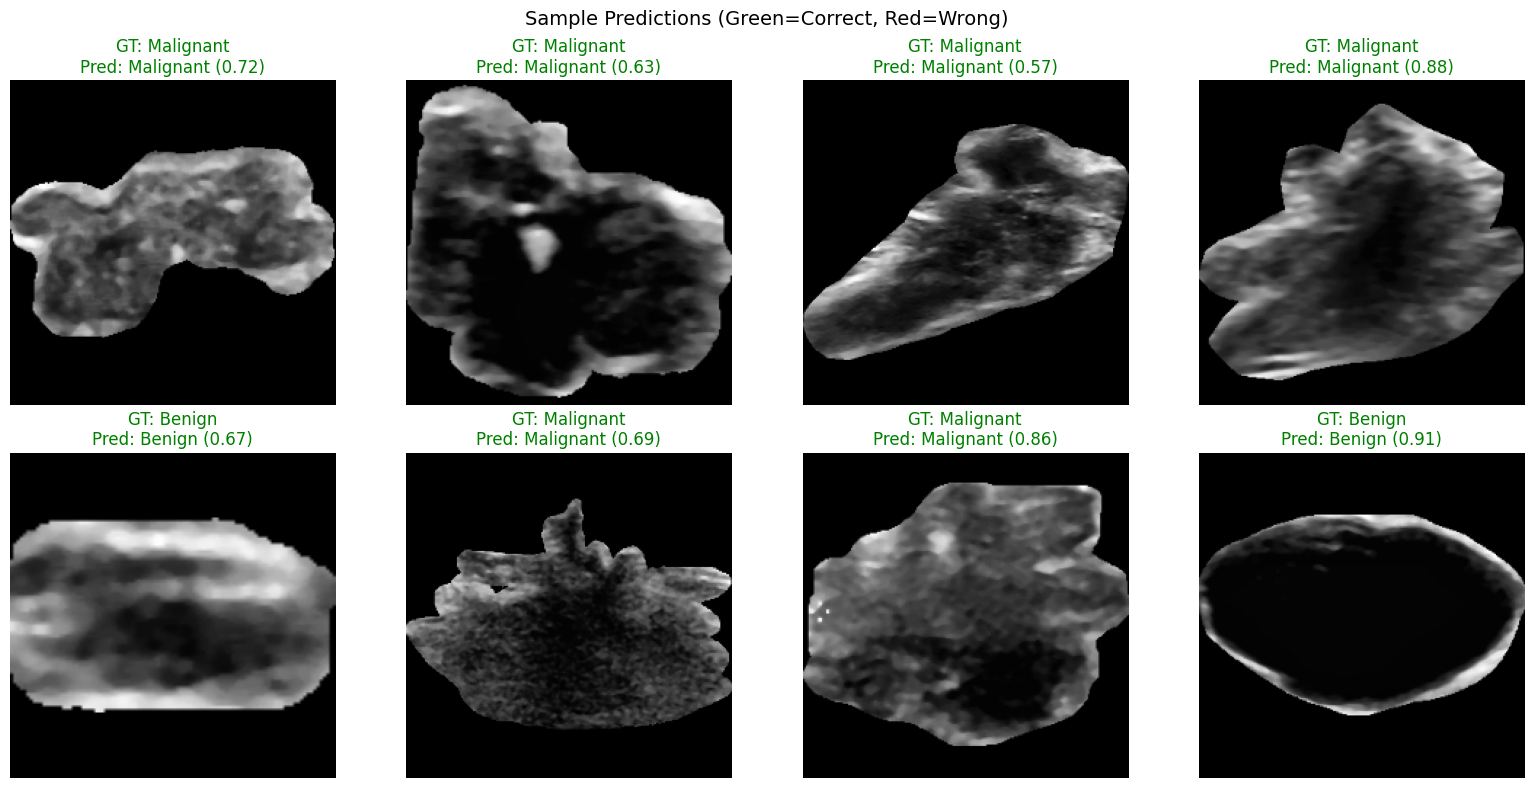

In [15]:
n_samples = 8
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

indices = np.random.choice(len(val_dataset), n_samples, replace=False)

model.eval()
with torch.no_grad():
    for i, idx in enumerate(indices):
        sample = val_dataset[idx]
        img = sample['image'].unsqueeze(0).to(Config.DEVICE)
        label = sample['label'].item()
        
        logits = model(img)
        probs = F.softmax(logits, dim=1)
        pred = torch.argmax(logits, dim=1).item()
        conf = probs[0, pred].item()
        
        # Display
        img_display = sample['image'][0].numpy()  # First channel
        img_display = (img_display - img_display.min()) / (img_display.max() - img_display.min())
        
        axes[i].imshow(img_display, cmap='gray')
        
        label_name = 'Benign' if label == 0 else 'Malignant'
        pred_name = 'Benign' if pred == 0 else 'Malignant'
        color = 'green' if label == pred else 'red'
        
        axes[i].set_title(f"GT: {label_name}\nPred: {pred_name} ({conf:.2f})", color=color)
        axes[i].axis('off')

plt.suptitle('Sample Predictions (Green=Correct, Red=Wrong)', fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
def load_ensemble_models(num_folds, model_class, device, weights_pattern='best_classification_fold{}.pt'):
    models = []
    print(f"🔄 Caricamento di {num_folds} modelli per l'ensemble...")
    
    for i in range(num_folds):
        model = model_class(
            num_classes=Config.NUM_CLASSES,
            dropout=Config.DROPOUT,
            pretrained=False
        )
        
        weight_path = weights_pattern.format(i)
        
        if os.path.exists(weight_path):
            checkpoint = torch.load(weight_path, map_location=device, weights_only=False)
            if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
                model.load_state_dict(checkpoint['model_state_dict'])
            else:
                model.load_state_dict(checkpoint)
            
            model.to(device)
            model.eval()
            models.append(model)
            print(f"  ✅ Modello Fold {i} caricato.")
        else:
            print(f"  ❌ ATTENZIONE: Pesi non trovati: {weight_path}")
            
    if not models:
        raise ValueError("Nessun modello caricato! Controlla il percorso dei pesi.")
        
    return models


def apply_tta_ensemble(img_tensor, models, device, use_tta=True):
    if not use_tta:

        with torch.no_grad():
            all_probs = []
            for model in models:
                logits = model(img_tensor.to(device))
                probs = F.softmax(logits, dim=1)
                all_probs.append(probs)
            return torch.mean(torch.stack(all_probs), dim=0)
    

    tta_weights = [0.4, 0.2, 0.2, 0.2]
    
    img = img_tensor.to(device)
    b, c, h, w = img.shape
    
    imgs_orig = img
    
    imgs_hflip = torch.flip(img, dims=[3])
    
    imgs_vflip = torch.flip(img, dims=[2])
    
    crop_size = int(h * 0.9)
    start = (h - crop_size) // 2
    imgs_cropped = img[:, :, start:start+crop_size, start:start+crop_size]
    imgs_zoom = F.interpolate(imgs_cropped, size=(h, w), mode='bilinear', align_corners=False)
    
    tta_batch = torch.cat([imgs_orig, imgs_hflip, imgs_vflip, imgs_zoom], dim=0)
    
    with torch.no_grad():
        ensemble_probs = torch.zeros(b, Config.NUM_CLASSES, device=device)
        
        for model in models:
            logits = model(tta_batch)
            probs = F.softmax(logits, dim=1)  # (4*B, num_classes)
            
            p_orig = probs[0:b]
            p_hflip = probs[b:2*b]
            p_vflip = probs[2*b:3*b]
            p_zoom = probs[3*b:4*b]
            
            model_avg = (p_orig * tta_weights[0] +
                        p_hflip * tta_weights[1] + 
                        p_vflip * tta_weights[2] + 
                        p_zoom * tta_weights[3])
            
            ensemble_probs += model_avg
        
        final_probs = ensemble_probs / len(models)
    
    return final_probs


print("✅ Funzioni TTA + Ensemble caricate")

✅ Funzioni TTA + Ensemble caricate



🚀 INFERENCE POTENZIATA: TTA + ENSEMBLE

🔄 Caricamento di 5 modelli per l'ensemble...
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
  ✅ Modello Fold 0 caricato.
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ EfficientNet-B3 V2 IMPROVED MODEL initialized
   Features dim: 1536
   ✅ ROI-Focused Attention (ignores gray background)
   ✅ Edge-Aware Branch (separate processing)
   ✅ Multi-Head Spatial Attention (multiple scales)
   ✅ Feature Fusion (spatial + edge)
   Main: Benign vs Malignant (2 classes)
   Aux: Edge Regularity (for discriminative learning)
  ✅ Modello Fold 1 caricato.
   Backbone output: torch.Size([1, 1536, 7, 7])

✨ Eff

TTA+Ensemble Inference:   0%|          | 0/12 [00:00<?, ?it/s]


📊 CONFRONTO RISULTATI

   Balanced Accuracy (Singolo modello, no TTA): 0.8992
   Balanced Accuracy (Ensemble + TTA):           0.9384

   Status: ✅ TARGET ACHIEVED!


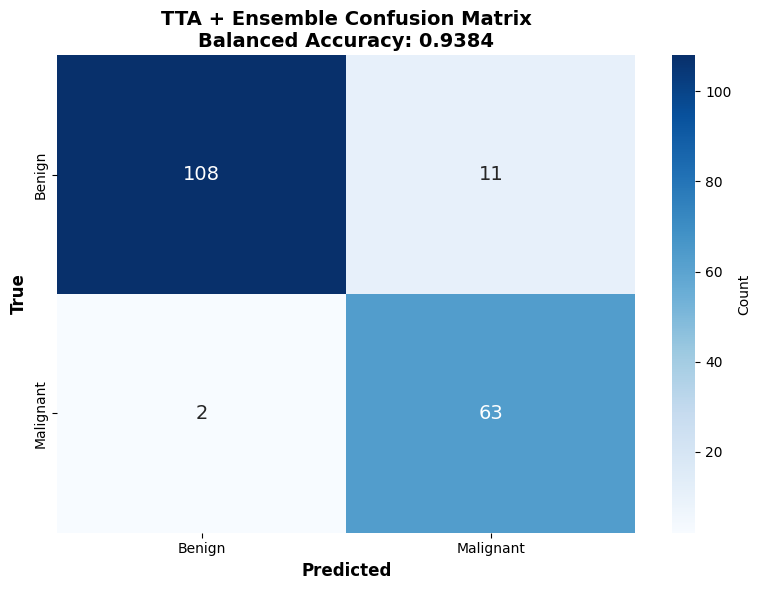


CLASSIFICATION REPORT (TTA + Ensemble)
              precision    recall  f1-score   support

      Benign     0.9818    0.9076    0.9432       119
   Malignant     0.8514    0.9692    0.9065        65

    accuracy                         0.9293       184
   macro avg     0.9166    0.9384    0.9249       184
weighted avg     0.9357    0.9293    0.9302       184



In [17]:
ensemble_models = load_ensemble_models(
    num_folds=5,
    model_class=EfficientNetWithROIAwareCBAM,
    device=Config.DEVICE,
    weights_pattern='best_classification_fold{}.pt'
)

try:
    _ = val_dataset
except NameError:
    major_labels = np.array([p['major_label'] for p in train_data])
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(np.arange(len(train_data)), major_labels)):
        if fold_idx == 4:
            val_patients = [train_data[i] for i in val_idx]
            val_dataset = LesionClassificationDataset(val_patients, augment=False)
            break

val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)

print("\n🔬 Running inference con 4-View TTA + 5-Model Ensemble...")

all_preds_tta = []
all_labels_tta = []
all_probs_tta = []

for batch in tqdm(val_loader, desc="TTA+Ensemble Inference"):
    images = batch['image']
    labels = batch['label'].numpy()
    
    probs = apply_tta_ensemble(images, ensemble_models, Config.DEVICE, use_tta=True)
    preds = torch.argmax(probs, dim=1).cpu().numpy()
    
    all_preds_tta.extend(preds)
    all_labels_tta.extend(labels)
    all_probs_tta.extend(probs.cpu().numpy())

ba_tta = balanced_accuracy_score(all_labels_tta, all_preds_tta)

print(f"\n{'='*80}")
print("📊 CONFRONTO RISULTATI")
print(f"{'='*80}")

try:
    ba_no_tta = fold_results['final_bal_acc'][-1]
    print(f"\n   Balanced Accuracy (Singolo modello, no TTA): {ba_no_tta:.4f}")
except:
    pass

print(f"   Balanced Accuracy (Ensemble + TTA):           {ba_tta:.4f}")
print(f"\n   Status: {'✅ TARGET ACHIEVED!' if ba_tta >= 0.75 else '❌ Below target'}")

cm_tta = confusion_matrix(all_labels_tta, all_preds_tta)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_tta, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar_kws={'label': 'Count'},
            ax=ax, annot_kws={'size': 14})
ax.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax.set_ylabel('True', fontsize=12, fontweight='bold')
ax.set_title(f'TTA + Ensemble Confusion Matrix\nBalanced Accuracy: {ba_tta:.4f}', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n{'='*80}")
print("CLASSIFICATION REPORT (TTA + Ensemble)")
print(f"{'='*80}")
print(classification_report(all_labels_tta, all_preds_tta, 
                           target_names=['Benign', 'Malignant'], digits=4))